In [ ]:
!nvidia-smi

Wed Oct  7 08:10:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

!git clone -b ayan https://github.com/AyanAlam99/llm-emotion-representations.git /content/llm-emotion-representations
%cd /content/llm-emotion-representations

fatal: destination path '/content/llm-emotion-representations' already exists and is not an empty directory.
/content/llm-emotion-representations


In [ ]:
!pip install -q -U "transformers>=5.18.0" accelerate
!pip install -q -e . --no-deps --ignore-requires-python

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for llm-emotion-representations (pyproject.toml) ... done


In [ ]:
import json, sys, time, torch
from pathlib import Path

sys.path.insert(0, "/content/llm-emotion-representations/src")
from emotion_vectors.config import GENERATION_KWARGS, MODEL_ID, SEED
from emotion_vectors.prompts import build_manifest
from emotion_vectors.generation import (
    load_model_and_tokenizer, render_chat_prompt, validate_generation,
    _generation_kwargs, _input_device,
)

# ---------------- settings ----------------
RUN_DIR = Path("/content/drive/MyDrive/emotion_runs/qwen35_2b_fp32")
DTYPE = "float32"
BATCH_SIZE = 8
LIMIT = None
# ---------------- 1. setup aur resume ----------------
RUN_DIR.mkdir(parents=True, exist_ok=True)
manifest = build_manifest()
man_path = RUN_DIR / "manifest.jsonl"
if man_path.exists():
    saved = [json.loads(l) for l in open(man_path, encoding="utf-8") if l.strip()]
    assert saved == manifest, "Saved manifest current config se match nahi karta. Naya RUN_DIR use karo."
else:
    with open(man_path, "w", encoding="utf-8") as f:
        for row in manifest:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")

gen_path = RUN_DIR / "generations.jsonl"
done = set()
if gen_path.exists():
    done = {json.loads(l)["sample_id"] for l in open(gen_path, encoding="utf-8") if l.strip()}
rows = manifest if LIMIT is None else manifest[:LIMIT]
pending = [r for r in rows if r["sample_id"] not in done]
print(f"{len(pending)} pending out of {len(rows)} selected")

# ---------------- model + tokenizer ----------------
model, tok = load_model_and_tokenizer(MODEL_ID, torch_dtype=DTYPE)
tok.padding_side = "left"                     # generation ke liye padding left side pe
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

gen_kwargs = _generation_kwargs(tok)
gen_kwargs.pop("presence_penalty", None)      # agar purana config clone hua ho toh crash se bachao
logged_params = {k: v for k, v in GENERATION_KWARGS.items() if k != "presence_penalty"}
stop_ids = {tok.eos_token_id, tok.pad_token_id} - {None}


0 pending out of 1100 selected


config.json:   0%|          | 0.00/2.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.75k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/64.5k [00:00<?, ?B/s]

model.safetensors-00001-of-00001.safeten(…): reconstructing file:   0%|          |  0.00B / 4.55GB            

model.safetensors-00001-of-00001.safeten(…): downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

In [ ]:

# ---------------- 2. ek batch generate karna ----------------
@torch.inference_mode()
def generate_batch(batch, batch_seed):
    prompts = [render_chat_prompt(tok, r["prompt"]) for r in batch]
    enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False)
    enc = {k: v.to(_input_device(model)) for k, v in enc.items()}

    torch.manual_seed(batch_seed)
    torch.cuda.manual_seed_all(batch_seed)
    out = model.generate(**enc, **gen_kwargs).cpu()

    padded_len = enc["input_ids"].shape[1]
    ids_cpu = enc["input_ids"].cpu()
    mask_cpu = enc["attention_mask"].cpu().bool()

    records = []
    for i, (row, rendered) in enumerate(zip(batch, prompts)):
        prompt_ids = ids_cpu[i][mask_cpu[i]].tolist()             # left padding hatao
        new_ids = out[i, padded_len:].tolist()
        cut = next((j for j, t in enumerate(new_ids) if t in stop_ids), len(new_ids))
        response_ids = new_ids[:cut]                               # pehle EOS/pad pe kaato
        full_ids = prompt_ids + response_ids                       # padding-free sequence

        # check: padding hatane ke baad prompt_ids wahi hone chahiye jo akele tokenize karne pe aate
        assert prompt_ids == tok(rendered, add_special_tokens=False)["input_ids"], row["sample_id"]

        rec = {
            **row,
            "rendered_prompt": rendered,
            "response": tok.decode(response_ids, skip_special_tokens=True).strip(),
            "prompt_ids": prompt_ids,
            "response_ids": response_ids,
            "full_ids": full_ids,
            "response_start": len(prompt_ids),
            "response_end": len(full_ids),
            "generation_parameters": dict(logged_params),
            "model_id": MODEL_ID,
            "thinking_enabled": False,
            "batch_seed": batch_seed,
        }
        rec["validation"] = validate_generation(rec)
        records.append(rec)
    return records

# ---------------- 3. main loop ----------------
t_start = time.time()
with open(gen_path, "a", encoding="utf-8") as f:
    for start in range(0, len(pending), BATCH_SIZE):
        batch = pending[start:start + BATCH_SIZE]
        t0 = time.time()
        recs = generate_batch(batch, batch_seed=SEED + start)
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
        f.flush()
        n_valid = sum(r["validation"]["valid"] for r in recs)
        print(f"{start + len(batch)}/{len(pending)}  valid {n_valid}/{len(batch)}  {time.time() - t0:.1f}s")
print(f"total {time.time() - t_start:.1f}s, saved to {gen_path}")

total 0.0s, saved to /content/drive/MyDrive/emotion_runs/qwen35_2b_fp32/generations.jsonl


In [ ]:
# 1. Generation wala model GPU se hatao (warna T4 pe memory khatam ho jaayegi)
import gc, torch
try:
    del model
except NameError:
    pass
gc.collect()
torch.cuda.empty_cache()

# 2. Repo folder mein jao aur check karo ki generation poora hua
%cd /content/llm-emotion-representations
!wc -l /content/drive/MyDrive/emotion_runs/qwen35_2b_fp32/generations.jsonl

# 3. PASS 2
!python scripts/extract_activations.py --run-dir /content/drive/MyDrive/emotion_runs/qwen35_2b_fp32 --torch-dtype float32

/content/llm-emotion-representations
1100 /content/drive/MyDrive/emotion_runs/qwen35_2b_fp32/generations.jsonl
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 320/320 [00:12<00:00, 24.68it/s]
[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
extracted 1/1019: neutral_a_pet_A_0042 shape=(24, 2048)
extracted 2/1019: anger_a_pet_A_0042 shape=(24, 2048)
extracted 3/1019: annoyance_a_pet_A_0042 shape=(24, 2048)
extracted 4/1019: fear_a_pet_A_0042 shape=(24, 2048)
extracted 5/1019: nervousness_a_pet_A_0042 shape=(24, 2048)
extracted 6/1019: sadness_a_pet_A_

In [ ]:
import json, collections
RUN = "/content/drive/MyDrive/emotion_runs/qwen35_2b_fp32"
all_recs = [json.loads(l) for l in open(f"{RUN}/generations.jsonl", encoding="utf-8")]

In [ ]:
import sys, torch
import matplotlib.pyplot as plt
sys.path.insert(0, "/content/llm-emotion-representations/src")
from emotion_vectors.vectors import build_emotion_vectors

recs = [r for r in all_recs if r["validation"]["valid"]]
acts = {r["sample_id"]: torch.load(f"{RUN}/activations/{r['sample_id']}.pt") for r in recs}
raw, unit, pair_ids = build_emotion_vectors(acts, recs)
print({e: len(p) for e, p in pair_ids.items()})      # upar wali table jaise numbers aane chahiye



{'anger': 81, 'annoyance': 97, 'fear': 85, 'nervousness': 100, 'sadness': 98, 'disappointment': 93, 'joy': 87, 'excitement': 93, 'admiration': 92, 'gratitude': 93}


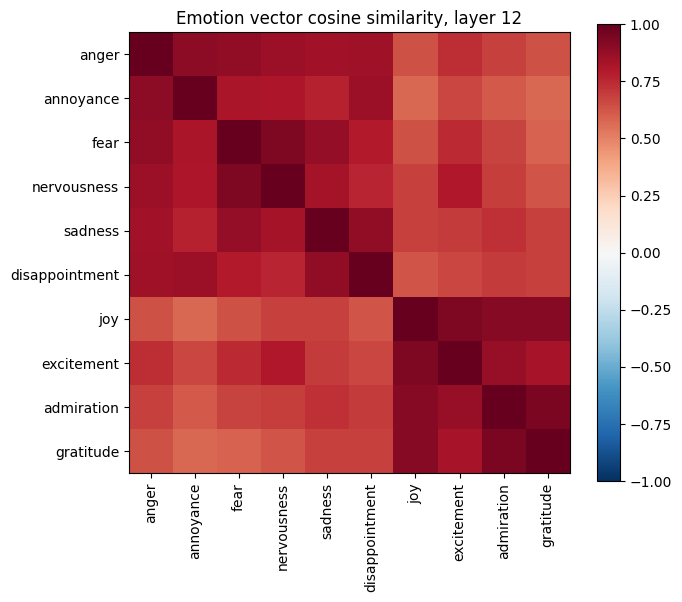

In [ ]:
LAYER = 12
E = list(unit)
M = torch.stack([unit[e][LAYER] for e in E])
C = (M @ M.T).numpy()                                 # unit vectors ka product = cosine
plt.figure(figsize=(7, 6))
plt.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar()
plt.xticks(range(len(E)), E, rotation=90); plt.yticks(range(len(E)), E)
plt.title(f"Emotion vector cosine similarity, layer {LAYER}")
plt.tight_layout(); plt.savefig(f"{RUN}/heatmap_layer{LAYER}.png", dpi=200); plt.show()

In [ ]:
from emotion_vectors.generation import load_model_and_tokenizer, render_chat_prompt

model, tok = load_model_and_tokenizer(torch_dtype="float32")
layers = model.model.layers

@torch.no_grad()
def mean_token_norm(layer, n=20):
    norms = []
    for r in [r for r in recs if r["condition"] == "neutral"][:n]:
        ids = torch.tensor([r["full_ids"]], device=model.device)
        hs = model(input_ids=ids, output_hidden_states=True, use_cache=False).hidden_states
        h = hs[layer + 1][0, r["response_start"]:r["response_end"]]
        norms.append(h.float().norm(dim=-1).mean().item())
    return sum(norms) / len(norms)

NORM = mean_token_norm(LAYER)
print("layer", LAYER, "typical token norm:", round(NORM, 2))

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


layer 12 typical token norm: 6.42


In [ ]:
def make_hook(vec):
    def hook(module, inputs, output):
        if isinstance(output, tuple):
            return (output[0] + vec.to(output[0].dtype),) + output[1:]
        return output + vec.to(output.dtype)
    return hook


In [ ]:
@torch.no_grad()
def generate(prompt, vec=None, max_new_tokens=80):
    text = render_chat_prompt(tok, prompt)
    enc = tok(text, return_tensors="pt", add_special_tokens=False).to(model.device)
    handle = layers[LAYER].register_forward_hook(make_hook(vec)) if vec is not None else None
    try:
        out = model.generate(**enc, do_sample=False, max_new_tokens=max_new_tokens,
                             pad_token_id=tok.pad_token_id)
    finally:
        if handle is not None:
            handle.remove()
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

p0 = "Write a short paragraph describing a person's morning routine."
base = generate(p0)
assert generate(p0, torch.zeros(2048, device=model.device)) == base, "hook bug!"
print("BASELINE:\n", base)

[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


BASELINE:
 The morning begins with the soft, rhythmic sound of the alarm clock piercing the silence, followed by the deliberate act of stretching to wake up the body. As the sun filters through the curtains, casting a warm glow across the room, the person steps out the door, grabbing a fresh cup of coffee and a bag of fresh fruit. They walk briskly down the street, the city waking up around


In [ ]:
for e in ["joy", "sadness","anger","fear"]:
    for a in [0.25, 0.5, 1.0, 2.0]:
        vec = (a * NORM * unit[e][LAYER]).to(model.device)
        print(f"===== {e}, alpha={a} =====")
        print(generate(p0, vec), "\n")

===== joy, alpha=0.25 =====
As the first light of dawn breaks through the curtains, a sense of calm washes over the room, signaling the start of a new day. The morning routine begins with a deep, soulful breath, followed by the gentle sound of water filling a glass and the aroma of fresh coffee filling the air. With a smile, the person steps out of bed, their movements light and joyful, and immediately 

===== joy, alpha=0.5 =====
There's nothing quite like the first light of dawn to wake the soul, starting with a deep, soulful breath that fills the chest. As I stretch, my body melts into the morning air, and I feel the world expanding around me. I reach for a glass of water, feeling the warmth of it on my tongue, and then I'm soaring through the sky, carrying a secret joy that 

===== joy, alpha=1.0 =====
It all begins in the very soul of my spirit, starting with a cascade of colors that dance through my very chest—a melody I can't quite name! This is the moment my soul takes flight, 